### 朴素贝叶斯算法
利用概率值进行分类的机器学习算法，核心是贝叶斯定理+条件独立性假设
朴素：不考虑特征之间的关联性（联合分布、条件概率等）

**数学原理 贝叶斯公式**
贝叶斯公式用于计算在已知条件下某件事情发生的概率
$$
P(A|B) = \frac{[P(B|A) × P(A)]}{P(B)}
$$


- P(A|B) 后验概率，即看到当前这个样本的特征B之后，其属于类别A的概率
- P(A) 先验概率，看到任何特征之前，对类别A的固有认知
- P(B|A) 似然概率，*生成式的关键。表示在类别A里，特征B出现的概率有多大、
- P(B) 证据因子，归一化常数
- 
**P(B)全概率展开**
$$
P(B) = \sum_{k=1}^KP(B|A_k)*P(A_k)
$$
分类问题时
如果有$A_1,A_2,...,A_k$ K钟类别，那么特征B出现的总概率等于所有类别下出现概率的加权和


**朴素贝叶斯算法**
解决在已知特征X的情况下，其属于类别$C_k$的概率是多少
* 朴素贝叶斯假设：在给定类别Y的条件下，所有特征$X_1,X_2,...,X_n$之间相互独立
即联合概率$P(X_1,X_2,...,X_n|Y)$可以简化为每个特征概率的连乘积
$$
P(X|Y) = P(X_1,X_2,...,X_n|Y) = \prod_{i=1}^nP(X_i|Y)
$$

例子：朴素贝叶斯认为在确定了“性别”后，“身高”和“体重”就没有关联了。
这与现实正好相反，但是其在实际分类中并不影响结果，并且极大简化了计算

**多项式朴素贝叶斯**
-离散型特征（文本词频）

$$
P(x_i|Y) = \frac{N_{yi}+α}{N_y+α·n}
$$

**高斯朴素贝叶斯**
-连续型特征（连续数值）
不再统计频数，假设该特征在某个类别下服从正态分布（即高斯分布）只需要计算每个类别下该特征的均值和方差
$$
P(x_i|Y) = \frac{1}{\sqrt{2\pi\sigma_Y^2}} \exp\left(-\frac{(x_i - \mu_Y)^2}{2\sigma_Y^2}\right)
$$


训练集前5行（0=男, 1=女）：
       Height     Weight  Gender
0  176.545302  70.962365     0.0
1  181.978983  72.615419     0.0
2  158.915322  63.184843     1.0
3  166.103360  60.101330     1.0
4  164.280149  47.645406     1.0

先验概率 P(男) = 0.481, P(女) = 0.519

模型参数（从训练集估计）：
男性: 身高均值=174.8, 方差=35.6 | 体重均值=70.3, 方差=61.4
女性: 身高均值=163.6, 方差=25.4 | 体重均值=55.5, 方差=37.3

新样本 (身高178cm, 体重72kg)：
属于男性的后验 (未归一化): 1.39e-03
属于女性的后验 (未归一化): 1.12e-06
预测结果：👨 男性

sklearn 预测结果: 男性
sklearn 概率输出: P(男)=0.999, P(女)=0.001

测试集准确率: 0.939


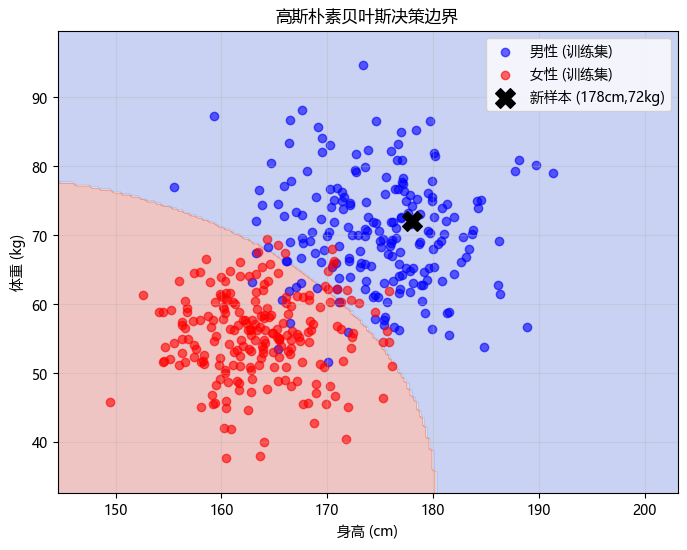

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

plt.rc('font', **{'family': 'Microsoft YaHei, SimHei'})
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('height_weight.csv')
X = df[['Height', 'Weight']].values
y = df['Gender'].values

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 查看训练集
df_train = pd.DataFrame(X_train, columns=['Height', 'Weight'])
df_train['Gender'] = y_train
print("\n训练集前5行（0=男, 1=女）：")
print(df_train.head())

prior_male = np.sum(y_train == 0) / len(y_train)
prior_female = np.sum(y_train == 1) / len(y_train)
print(f"\n先验概率 P(男) = {prior_male:.3f}, P(女) = {prior_female:.3f}")

male_mask = (y_train == 0)
female_mask = (y_train == 1)

# 男性统计
mu_height_male = np.mean(X_train[male_mask, 0])
var_height_male = np.var(X_train[male_mask, 0])
mu_weight_male = np.mean(X_train[male_mask, 1])
var_weight_male = np.var(X_train[male_mask, 1])

# 女性统计
mu_height_female = np.mean(X_train[female_mask, 0])
var_height_female = np.var(X_train[female_mask, 0])
mu_weight_female = np.mean(X_train[female_mask, 1])
var_weight_female = np.var(X_train[female_mask, 1])

print("\n模型参数（从训练集估计）：")
print(f"男性: 身高均值={mu_height_male:.1f}, 方差={var_height_male:.1f} | 体重均值={mu_weight_male:.1f}, 方差={var_weight_male:.1f}")
print(f"女性: 身高均值={mu_height_female:.1f}, 方差={var_height_female:.1f} | 体重均值={mu_weight_female:.1f}, 方差={var_weight_female:.1f}")

# 定义高斯概率密度函数
def gaussian_pdf(x, mu, var):
    return (1 / np.sqrt(2 * np.pi * var)) * np.exp(-(x - mu)**2 / (2 * var))

# 新样本
new_sample = np.array([178, 72])

# 计算似然
likelihood_height_male = gaussian_pdf(new_sample[0], mu_height_male, var_height_male)
likelihood_weight_male = gaussian_pdf(new_sample[1], mu_weight_male, var_weight_male)
likelihood_male = likelihood_height_male * likelihood_weight_male

likelihood_height_female = gaussian_pdf(new_sample[0], mu_height_female, var_height_female)
likelihood_weight_female = gaussian_pdf(new_sample[1], mu_weight_female, var_weight_female)
likelihood_female = likelihood_height_female * likelihood_weight_female

# 后验（未归一化，因为分母相同）
posterior_male = likelihood_male * prior_male
posterior_female = likelihood_female * prior_female

print(f"\n新样本 (身高178cm, 体重72kg)：")
print(f"属于男性的后验 (未归一化): {posterior_male:.2e}")
print(f"属于女性的后验 (未归一化): {posterior_female:.2e}")
print(f"预测结果：{'👨 男性' if posterior_male > posterior_female else '👩 女性'}")




gnb = GaussianNB()
gnb.fit(X_train, y_train)

pred = gnb.predict([new_sample])
pred_prob = gnb.predict_proba([new_sample])
print(f"\nsklearn 预测结果: {'男性' if pred[0] == 0 else '女性'}")
print(f"sklearn 概率输出: P(男)={pred_prob[0][0]:.3f}, P(女)={pred_prob[0][1]:.3f}")

# 测试集准确率
y_pred = gnb.predict(X_test)
print(f"\n测试集准确率: {accuracy_score(y_test, y_pred):.3f}")

# =================== 可视化决策边界 ===================
x_min, x_max = X[:, 0].min()-5, X[:, 0].max()+5
y_min, y_max = X[:, 1].min()-5, X[:, 1].max()+5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
Z = gnb.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_train[male_mask, 0], X_train[male_mask, 1], 
            c='blue', label='男性 (训练集)', alpha=0.6)
plt.scatter(X_train[female_mask, 0], X_train[female_mask, 1], 
            c='red', label='女性 (训练集)', alpha=0.6)
plt.scatter(178, 72, c='black', marker='X', s=200, label='新样本 (178cm,72kg)')
plt.xlabel('身高 (cm)')
plt.ylabel('体重 (kg)')
plt.title('高斯朴素贝叶斯决策边界')
plt.legend()
plt.grid(alpha=0.3)
plt.show()